# Statistical forecasting with SARIMA

In [1]:

from modules import utils
utils.configure_plotly_template(showlegend=True)

## Load data

In [2]:
path = '../../../data/statsmodels/AirPassengers_log.parquet'

In [3]:
import pandas as pd

df = pd.read_parquet(path).asfreq('ME')
df.columns = ["values"]
series = df["values"]
series.plot()

## Model fit

In [4]:
from statsmodels.tsa.arima.model import ARIMA

model = ARIMA(endog=series, order=(12, 1, 1))
model_fit = model.fit()
model_fit.summary()

/Users/sota/miniforge3/envs/time-series/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning:

Maximum Likelihood optimization failed to converge. Check mle_retvals



<class 'statsmodels.iolib.summary.Summary'>
"""
                               SARIMAX Results                                
==============================================================================
Dep. Variable:                 values   No. Observations:                  144
Model:                ARIMA(12, 1, 1)   Log Likelihood                 247.213
Date:                Tue, 27 May 2025   AIC                           -466.427
Time:                        22:40:09   BIC                           -424.947
Sample:                    01-31-1949   HQIC                          -449.572
                         - 12-31-1960                                         
Covariance Type:                  opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.1009      0.058      1.741      0.082      -0.013       0.214
ar.L2         -0.0627      0.055     -1.149      0.251      -0.170       0.044
ar.L3         -0.0008      0.049     -0.017      0.987      -0.097       0.095
ar.L4         -0.0544      0.052     -1.051      0.293      -0.156       0.047
ar.L5          0.0419      0.052      0.801      0.423      -0.061       0.144
ar.L6         -0.0262      0.046     -0.572      0.567      -0.116       0.064
ar.L7         -0.0210      0.052     -0.401      0.688      -0.124       0.082
ar.L8         -0.0873      0.052     -1.678      0.093      -0.189       0.015
ar.L9          0.0600      0.058      1.042      0.298      -0.053       0.173
ar.L10        -0.0622      0.055     -1.130      0.258      -0.170       0.046
ar.L11         0.0555      0.050      1.113      0.266      -0.042       0.153
ar.L12         0.8224      0.049     16.666      0.000       0.726       0.919
ma.L1         -0.4256      0.090     -4.754      0.000      -0.601      -0.250
sigma2         0.0016      0.000      7.513      0.000       0.001       0.002
===================================================================================
Ljung-Box (L1) (Q):                   0.09   Jarque-Bera (JB):                 2.95
Prob(Q):                              0.76   Prob(JB):                         0.23
Heteroskedasticity (H):               0.51   Skew:                             0.34
Prob(H) (two-sided):                  0.02   Kurtosis:                         3.15
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

In [5]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

model = SARIMAX(endog=series, order=(0, 1, 1), seasonal_order=(0, 1, 1, 12))
model_fit = model.fit()
model_fit.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                     SARIMAX Results                                      
==========================================================================================
Dep. Variable:                             values   No. Observations:                  144
Model:             SARIMAX(0, 1, 1)x(0, 1, 1, 12)   Log Likelihood                 244.696
Date:                            Tue, 27 May 2025   AIC                           -483.393
Time:                                    22:40:09   BIC                           -474.767
Sample:                                01-31-1949   HQIC                          -479.888
                                     - 12-31-1960                                         
Covariance Type:                              opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.4018      0.073     -5.503      0.000      -0.545      -0.259
ma.S.L12      -0.5570      0.096     -5.785      0.000      -0.746      -0.368
sigma2         0.0013      0.000      9.121      0.000       0.001       0.002
===================================================================================
Ljung-Box (L1) (Q):                   0.04   Jarque-Bera (JB):                 1.90
Prob(Q):                              0.84   Prob(JB):                         0.39
Heteroskedasticity (H):               0.58   Skew:                             0.02
Prob(H) (two-sided):                  0.08   Kurtosis:                         3.59
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

## Forecast

In [6]:
from modules import utils

df_forecast = utils.get_model_forecast(df, 'values', order=(12, 1, 1), horizon=96)
df_forecast = utils.get_model_forecast(df_forecast, 'values', order=(0, 1, 1), seasonal_order=(0, 1, 1, 12), horizon=96)

df_forecast.plot(color="variable")

/Users/sota/miniforge3/envs/time-series/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning:

Maximum Likelihood optimization failed to converge. Check mle_retvals



## Diagnostics and assumptions

In [7]:
model = SARIMAX(series, order=(0, 1, 1), seasonal_order=(0, 1, 1, 12))
model_fit = model.fit()

In [8]:
residuals = model_fit.resid[12+1:]
residuals

1950-02-28    0.039164
1950-03-31    0.013910
                ...   
1960-11-30   -0.027160
1960-12-31   -0.014970
Freq: ME, Length: 131, dtype: float64

### Autocorrelation

#### Plot

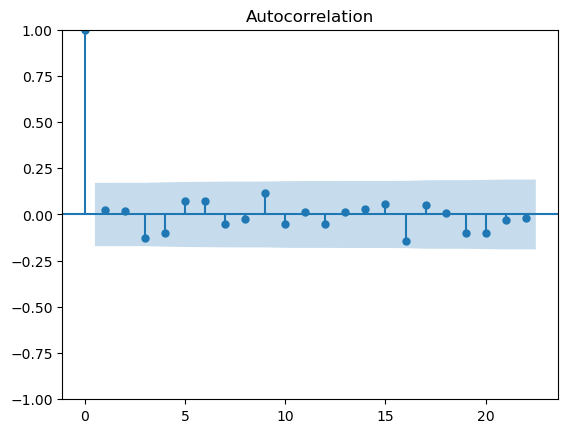

In [9]:
from statsmodels.graphics.tsaplots import plot_acf
plot_acf(residuals);

#### Test

In [10]:
from statsmodels.stats.diagnostic import acorr_ljungbox

acorr_ljungbox(residuals, lags=[10, 20, 30]).style

,lb_stat,lb_pvalue
10,8.039552,0.624973
20,15.689355,0.735699
30,26.225622,0.663567


### Normality

#### Plot

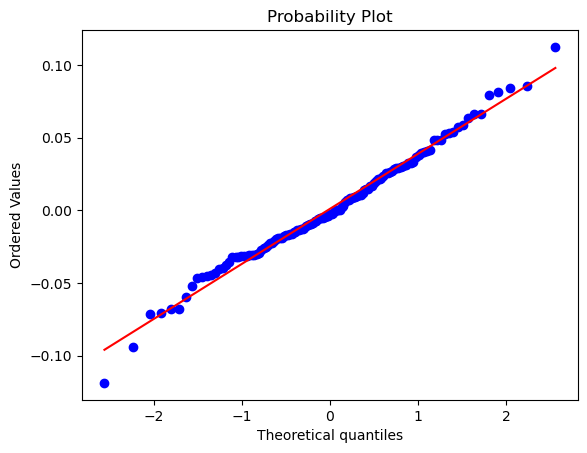

In [11]:
import matplotlib.pyplot as plt
from scipy import stats

fig, ax = plt.subplots()
stats.probplot(residuals, dist='norm', plot=ax);

#### Test

In [12]:
from scipy.stats import jarque_bera
jarque_bera(residuals)

SignificanceResult(statistic=np.float64(1.7633976316623514), pvalue=np.float64(0.41407887009253486))

### Homoscedasticity

#### Plot

In [13]:
residuals.plot()

#### Test

In [14]:
from statsmodels.stats.diagnostic import het_arch
het_arch(residuals)

(np.float64(13.665423974644233),
 np.float64(0.18880683261860565),
 1.4004775468212252,
 0.18942876319315047)